In [1]:
# Import modules

import pandas as pd
import lightgbm as lgb
import optuna
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np


In [7]:

all_data = pd.read_excel('/Users/W.Zhouhan/GitHub/Zhouhan-Predicting-Property-Prices/Master.xlsx')
print(all_data.head())

     price     priceper  year dateoftransfer         borough  postcode  \
0   490000  10208.33333  2022     2022-01-21  city of london  EC4A 1EP   
1   802500  10422.07792  2015     2015-10-16  city of london  EC1Y 0ST   
2  1200000  15189.87342  2019     2019-08-16  city of london  EC2Y 5AG   
3   626250  12780.61224  2015     2015-03-03  city of london  EC2Y 5AG   
4   938400  14436.92308  2015     2015-01-29  city of london  EC2Y 5AG   

                            transactionid  tfarea area_bin propertytype  ...  \
0  {DE2D0CDF-F797-51EE-E053-6C04A8C00671}    48.0       Q1            F  ...   
1  {23B6165E-9D97-FCF4-E050-A8C0620577FA}    77.0       Q2            F  ...   
2  {93E6821D-E5C2-40FD-E053-6B04A8C0C1DF}    79.0       Q3            F  ...   
3  {637497CC-ECF1-4AFD-B581-E63781F99F4B}    49.0       Q1            F  ...   
4  {74550953-773F-4D4F-A43E-1E79826CD95B}    65.0       Q2            F  ...   

   education    culture   central       ptal  crime_lagged_1yr  \
0  83.00

In [8]:
#Handle missing values
initial_rows = len(all_data.index)
all_data = all_data.dropna()
print(f"Number of rows removed for NA: {initial_rows - len(all_data.index)}")


Number of rows removed for NA: 247500


In [9]:
#Remove outliers >2.0million
all_data = all_data.drop(all_data[all_data['price'] >= 2000000].index)

print(f"Total number of rows for train/test/validation: {len(all_data.index)}")

Total number of rows for train/test/validation: 581471


In [10]:
#Define features and target: Uses price as as target and area as predictor
target = 'price'
features = ['tfarea', 'propertytype', 'education', 'culture', 'central', 'ptal', 'crime_lagged_1yr', 'cpih_lagged_1yr', 'unemployment_lagged_1yr', 'mortgage_lagged_1yr', 'avg_price_lagged_1yr']
categorical_features = 'propertytype'

#Split into train/test based on time
test_data = all_data[all_data['year'] == 2024]
train_full = all_data.drop(all_data[all_data['year'] == 2024].index)
print(f"Length of test data {len(test_data)}")
print(f"Length of training data {len(train_full)}")

# Train split
X_test = test_data[features].copy()
# Convert propertytype to category dtype (LightGBM requires category, not object/string)
X_test['propertytype'] = X_test['propertytype'].astype('category')
Y_test = test_data[target]

# Test split
X_train_full = train_full[features].copy()
# Convert propertytype to category dtype (LightGBM requires category, not object/string)
X_train_full['propertytype'] = X_train_full['propertytype'].astype('category')
Y_train_full = train_full[target]

Length of test data 33598
Length of training data 547873


In [11]:
# Train final model with best params

best_model = lgb.LGBMRegressor(**{'n_estimators': 181, 'learning_rate': 0.07671740076666826, 'num_leaves': 126, 'max_depth': 5, 'min_child_samples': 96, 'subsample': 0.9054034892479004, 'colsample_bytree': 0.8895689175370943})
best_model.fit(X_train_full, Y_train_full, categorical_feature=categorical_features)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006832 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1347
[LightGBM] [Info] Number of data points in the train set: 547873, number of used features: 11
[LightGBM] [Info] Start training from score 549459.992781
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

LGBMRegressor(colsample_bytree=0.8895689175370943,
              learning_rate=0.07671740076666826, max_depth=5,
              min_child_samples=96, n_estimators=181, num_leaves=126,
              subsample=0.9054034892479004)

In [12]:
#Evaluate model performance
Y_pred = best_model.predict(X_test)
rmse = mean_squared_error(Y_test, Y_pred, squared=False)
mean_price = Y_test.mean()
rmse_relative = (rmse / mean_price) * 100
mae = mean_absolute_error(Y_test, Y_pred)
mae_relative = (mae / mean_price) * 100
r2 = r2_score(Y_test, Y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"Mean price: {mean_price:.2f}")
print(f"RMSE as percentage of mean price: {rmse_relative:.2f}%")
print(f"MAE: {mae:.2f}")
print(f"MAE as percentage of mean price: {mae_relative:.2f}%")
print(f"R-squared: {r2:.2f}")

RMSE: 142632.57
Mean price: 592617.05
RMSE as percentage of mean price: 24.07%
MAE: 94419.00
MAE as percentage of mean price: 15.93%
R-squared: 0.80


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [13]:
# Calculate tolerance levels
percentage_errors = np.abs((Y_test - Y_pred) / Y_test) * 100

tolerances = [5, 10, 15, 20]

for tol in tolerances:
    within_tol = (percentage_errors <= tol).sum()
    pct = (within_tol / len(Y_test)) * 100
    print(f"Within {tol:2d}%: {pct:5.1f}% ({within_tol}/{len(Y_test)} properties)")



Within  5%:  22.8% (7659/33598 properties)
Within 10%:  43.6% (14661/33598 properties)
Within 15%:  60.2% (20226/33598 properties)
Within 20%:  72.3% (24306/33598 properties)


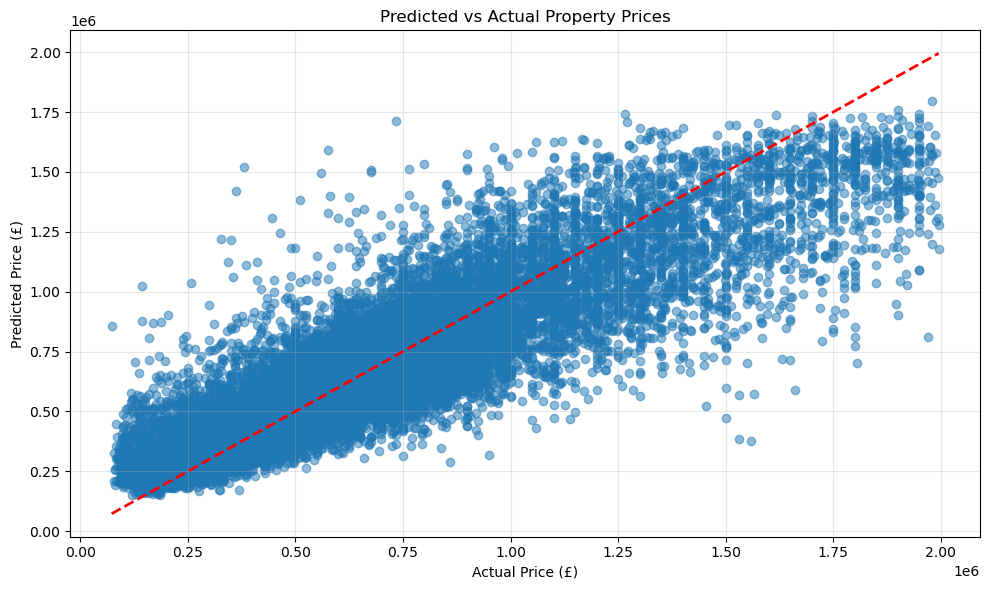

In [14]:
# Plot predicted vs actual
plt.figure(figsize=(10, 6))
plt.scatter(Y_test, Y_pred, alpha=0.5)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)  # perfect prediction line
plt.xlabel('Actual Price (£)')
plt.ylabel('Predicted Price (£)')
plt.title('Predicted vs Actual Property Prices')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

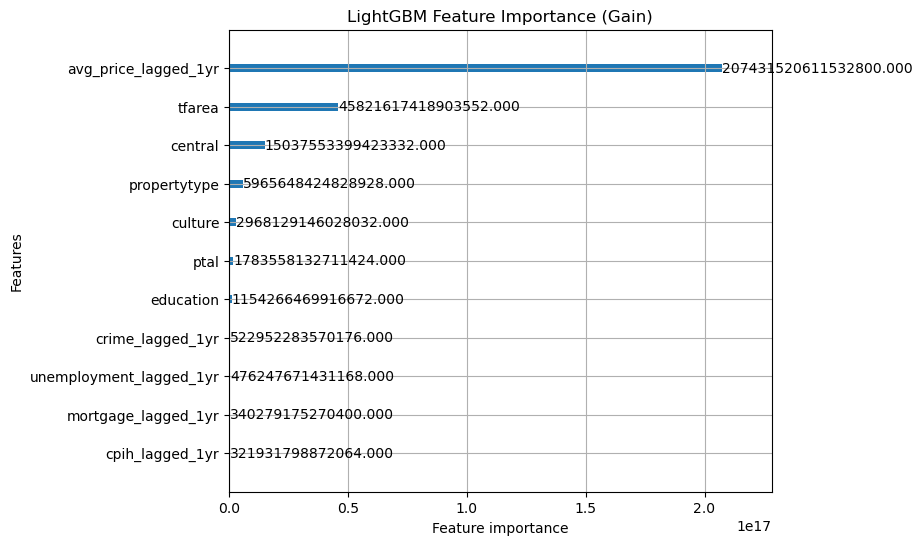

In [15]:
#Feature importance (Gain)
lgb.plot_importance(best_model, importance_type="gain", figsize=(7,6), title="LightGBM Feature Importance (Gain)")
plt.show()

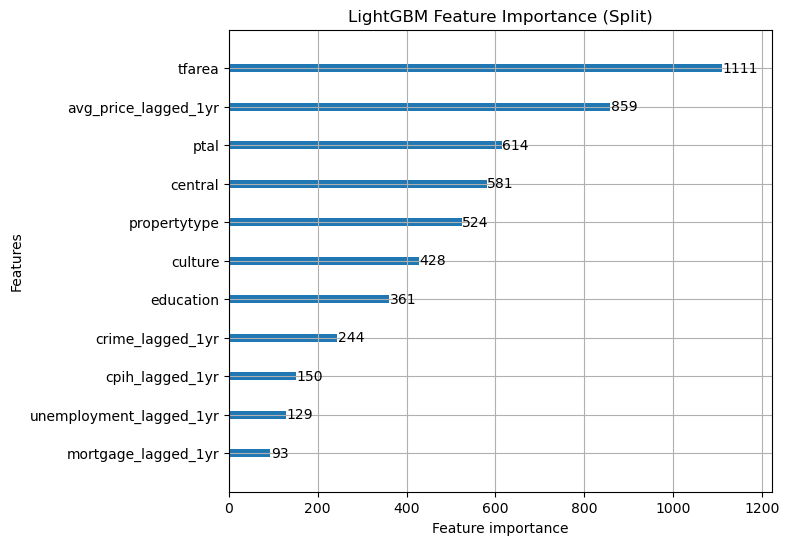

In [16]:
#Feature importance (Split)
lgb.plot_importance(best_model, importance_type="split", figsize=(7,6), title="LightGBM Feature Importance (Split)")
plt.show()

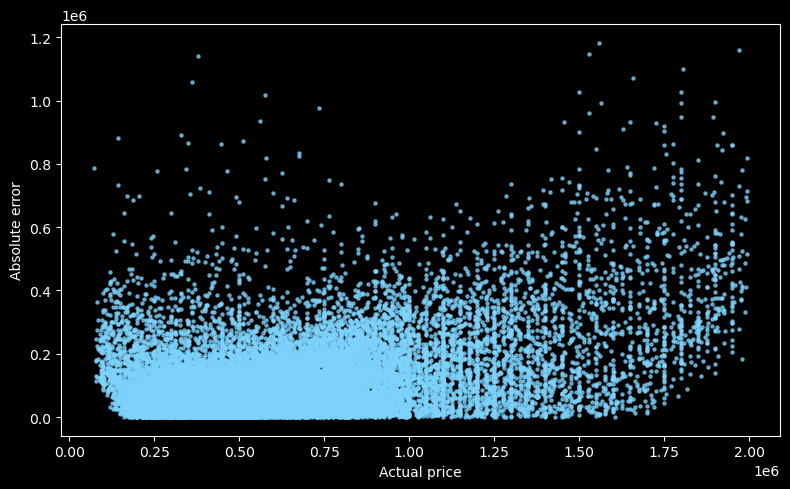

In [26]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor="black")
ax.set_facecolor("black")
ax.scatter(Y_test, np.abs(Y_test - Y_pred), s=5, color="#7dd3fc", alpha=0.7)
ax.set_xlabel("Actual price", color="white")
ax.set_ylabel("Absolute error", color="white")
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")
plt.tight_layout()


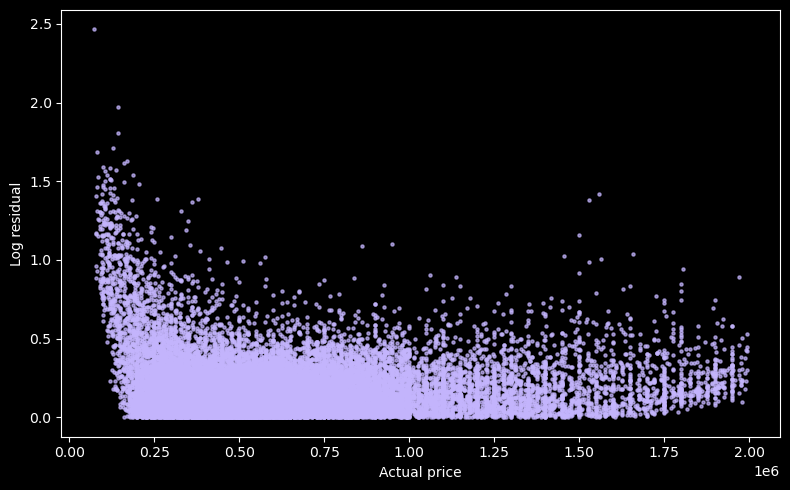

In [27]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor="black")
ax.set_facecolor("black")
ax.scatter(Y_test, np.abs(np.log(Y_test) - np.log(Y_pred)), s=5, color="#c4b5fd", alpha=0.7)
ax.set_xlabel("Actual price", color="white")
ax.set_ylabel("Log residual", color="white")
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")
plt.tight_layout()


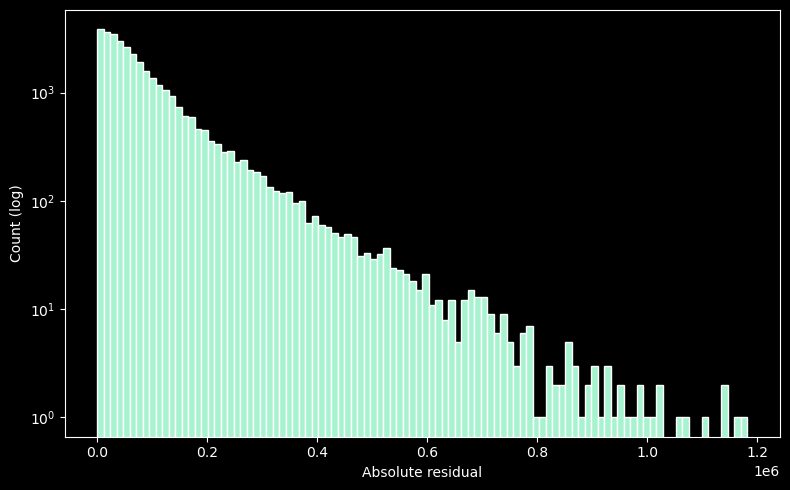

In [28]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor="black")
ax.set_facecolor("black")
ax.hist(np.abs(Y_test - Y_pred), bins=100, log=True, color="#a7f3d0", edgecolor="white")
ax.set_xlabel("Absolute residual", color="white")
ax.set_ylabel("Count (log)", color="white")
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")
plt.tight_layout()


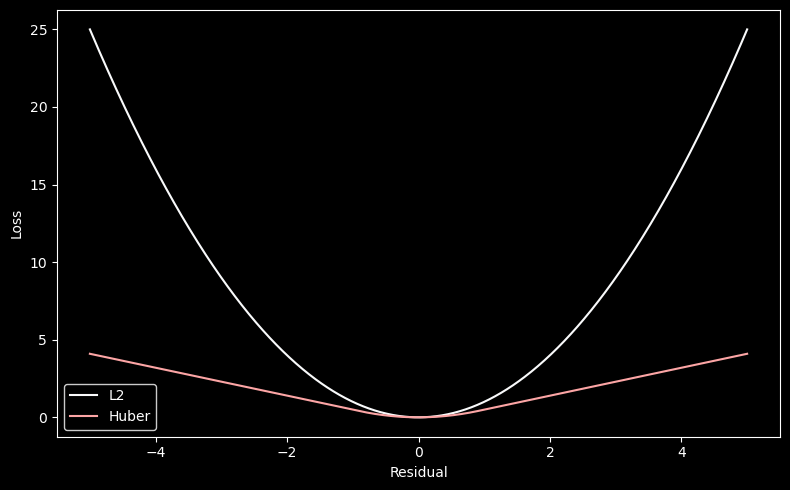

In [29]:
r = np.linspace(-5, 5, 1000)
delta = 0.9

l2 = r**2
huber = np.where(np.abs(r) <= delta,
                 0.5 * r**2,
                 delta * (np.abs(r) - 0.5 * delta))

fig, ax = plt.subplots(figsize=(8, 5), facecolor="black")
ax.set_facecolor("black")
ax.plot(r, l2, label="L2", color="#f9fafb")
ax.plot(r, huber, label="Huber", color="#fca5a5")
ax.legend(facecolor="black", edgecolor="white", labelcolor="white")
ax.set_xlabel("Residual", color="white")
ax.set_ylabel("Loss", color="white")
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")
plt.tight_layout()
